# Next-month household electricity forecasting — RECON-SL (Sri Lanka)

**Goal.** For every household, forecast next month's electricity consumption (kWh) from its own past readings. Accurate household-level forecasts support Ceylon Electricity Board (CEB) demand planning (the household forecasts sum to feeder- and region-level demand) and let households anticipate their bill under Sri Lanka's block tariff, where a few extra kWh can push a household into a more expensive block.

**Data.** `monthly_consumption.csv` from the RECON-SL dataset: `household_ID`, `month` (month-end date), `consumption` (kWh), Oct 2022 – Oct 2024.

**Approach.**
1. Data check → 2. Cleaning (logged) → 3. Leakage-free lag/rolling/calendar features → 4. Strict time-based split →
5. Baselines (naive, seasonal naive, ARIMA, Random Forest, XGBoost) vs. new models (LightGBM, CatBoost, time-ordered stacking) →
6. Test evaluation → 7. SHAP + partial dependence → 8. Save artefacts.

**Model choice and course rules.** RF, XGBoost, logistic regression and soft voting were taught in lectures, so they are used only as *existing-approach baselines*. The proposed models are **LightGBM** (histogram-based gradient boosting that grows trees leaf-wise), **CatBoost** (ordered boosting on symmetric/oblivious trees, which reduces target-leakage bias in boosting) and a **stacking ensemble** with a Ridge meta-learner trained on *time-ordered* out-of-fold predictions. No deep learning is used. No model runs with library-default hyperparameters: every value is either searched on the validation set or fixed with a stated reason.

All reusable logic lives in `src/` (cleaning, features, models, metrics, SHAP) so that the Streamlit app uses exactly the same code.


In [1]:
# --- Setup -------------------------------------------------------------------
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

from src import config
from src.data_prep import load_raw, parse_consumption, clean
from src.features import build_features, features_for_next_month, FEATURES
from src.evaluation import regression_metrics, rmse
from src import models as M
from src.explain import explain

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
np.random.seed(config.SEED)
pd.set_option("display.width", 160, "display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
for d in (config.FIGURES_DIR, config.RESULTS_DIR, config.MODELS_DIR, config.PROCESSED_DIR):
    d.mkdir(parents=True, exist_ok=True)

def savefig(name):
    """Save the current matplotlib figure to figures/ and show it inline."""
    plt.savefig(config.FIGURES_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

NOTEBOOK_START = time.time()

/Users/arani-xt/.venvs/recon-sl/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 1 — Data check

`consumption` is read as **text** on purpose: letting pandas coerce it would silently turn unusual strings into NaN before they can be inspected.


In [2]:
raw = load_raw()
print("Shape:", raw.shape)
print(raw.dtypes, "\n")

text = raw["consumption"].fillna("").str.strip()
parsed = parse_consumption(text)
n_months = raw.groupby("household_ID")["month"].nunique()

checks = pd.Series({
    "rows": len(raw),
    "households": raw["household_ID"].nunique(),
    "distinct months": raw["month"].nunique(),
    "first month": raw["month"].min().date(),
    "last month": raw["month"].max().date(),
    "missing household_ID / month": int(raw[["household_ID", "month"]].isna().sum().sum()),
    "blank consumption": int((text == "").sum()),
    "non-numeric strings (non-blank)": int(((text != "") & pd.to_numeric(text, errors="coerce").isna()).sum()),
    "  of which thousands separator e.g. '1,159'": int(text.str.contains(",", regex=False).sum()),
    "zero readings": int((parsed == 0).sum()),
    "households with >=1 zero": int(raw.loc[parsed == 0, "household_ID"].nunique()),
    "negative readings": int((parsed < 0).sum()),
    "exact duplicate rows": int(raw.duplicated().sum()),
    "duplicate (household, month)": int(raw.duplicated(["household_ID", "month"]).sum()),
    "households with < 25 months": int((n_months < 25).sum()),
})
checks.to_frame("value")

Shape: (101575, 3)
household_ID               str
month           datetime64[us]
consumption                str
dtype: object 



,value
rows,101575
households,4063
distinct months,25
first month,2022-10-31
last month,2024-10-31
missing household_ID / month,0
blank consumption,590
non-numeric strings (non-blank),57
"of which thousands separator e.g. '1,159'",57
zero readings,2332


In [3]:
# Distribution and outlier statistics of the parsed (non-zero) readings
pos = parsed[parsed > 0]
q = pos.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.995, 0.999]).round(1)
iqr_fence = pos.quantile(0.75) + 1.5 * (pos.quantile(0.75) - pos.quantile(0.25))
print(pos.describe().round(1).to_string())
print("\nPercentiles:\n" + q.to_string())
print(f"\nIQR (1.5x) upper fence = {iqr_fence:.1f} kWh -> flags {(pos > iqr_fence).sum()} readings "
      f"({(pos > iqr_fence).mean():.1%}); far too many for a right-skewed usage distribution.")
print(f"Readings > 1000 kWh: {(pos > 1000).sum()}; max = {pos.max():.0f}")

count    98653.0
mean       125.0
std        122.2
min          1.0
25%         63.0
50%         98.0
75%        150.0
max       3025.0

Percentiles:
0.010       3.0
0.050      19.0
0.250      63.0
0.500      98.0
0.750     150.0
0.950     309.0
0.990     582.0
0.995     774.7
0.999    1408.8

IQR (1.5x) upper fence = 280.5 kWh -> flags 6173 readings (6.3%); far too many for a right-skewed usage distribution.
Readings > 1000 kWh: 244; max = 3025


In [4]:
# Are the comma-formatted values and the extremes plausible for their households?
work = raw.assign(v=parsed.where(parsed > 0))
hh_med = work.groupby("household_ID")["v"].median()

comma = work[text.str.contains(",", regex=False)]
ratio = comma["v"] / comma["household_ID"].map(hh_med)
print("Comma-formatted values / household median:", ratio.describe().round(2).to_dict())

big = work[work["v"] > 1000].groupby("household_ID").size()
print(f"\nHouseholds with readings > 1000 kWh: {len(big)}")
print("Number of such months per household:", big.value_counts().sort_index().to_dict())
top = work.loc[work["v"].idxmax()]
print(f"\nLargest reading: {top.household_ID} {top.month:%Y-%m} = {top.v:.0f} kWh "
      f"(household median {hh_med[top.household_ID]:.0f})")

zero_hh = work[parsed == 0].groupby("household_ID").size()
print(f"\nHouseholds with >= 6 zero months: {(zero_hh >= 6).sum()}, >= 20 zero months: {(zero_hh >= 20).sum()}")

Comma-formatted values / household median: {'count': 57.0, 'mean': 1.62, 'std': 2.79, 'min': 0.73, '25%': 0.99, '50%': 1.16, '75%': 1.36, 'max': 22.02}

Households with readings > 1000 kWh: 36
Number of such months per household: {1: 14, 2: 4, 3: 4, 4: 1, 6: 2, 7: 1, 10: 1, 13: 1, 14: 1, 15: 1, 17: 1, 23: 3, 24: 1, 25: 1}

Largest reading: ID2759 2023-01 = 3025 kWh (household median 425)

Households with >= 6 zero months: 127, >= 20 zero months: 35


**Findings that shape the cleaning:**

* The panel is **complete and balanced**: every household has all 25 months, with no duplicates and no gaps. "Short histories" therefore come only from missing or zero readings, not from absent rows.
* All non-numeric strings are **thousands-formatted numbers** (`"1,159"`). Their ratio to the household's own median is about 1.16, so they are genuine readings. `pd.to_numeric(errors="coerce")` would have deleted 57 of the highest real values, so they are parsed by stripping the comma.
* **Zeros** (2.3% of readings) are concentrated: a few dozen households are zero for most of the period (likely disconnected, vacant or faulty meters).
* **Extremes have two different causes.** Some households exceed 1,000 kWh *every month* (probably small businesses or large homes; a real, persistent level), while others show one isolated spike, e.g. 3,025 kWh in a household whose median is 425. A single global threshold cannot tell these apart.
* The IQR rule would flag about 6% of readings, which is inappropriate for a right-skewed consumption distribution.


## Step 2 — Preprocessing

| Step | Decision | Justification |
|---|---|---|
| Parse | strip whitespace and thousands separators, then convert to numeric | recovers 57 genuine readings; blanks become missing |
| Zeros | treated as **missing** | a household connected to the grid uses at least a fridge; a 0 kWh month is a meter, billing or estimation fault, and training on it would teach the model that consumption can suddenly vanish |
| Sparse households | **drop** households with < 12 valid months | for a household that is zero for 20 of 25 months, a "median imputation" would fabricate most of its series from 1–5 readings; 12 months is the minimum needed for a genuine `lag_12` |
| Outliers | **clip spikes above 5× the household's own median** (chosen on validation, see below) | targets isolated spikes while keeping persistent heavy users intact; 5× is far beyond normal seasonal swings (on average, monthly readings stay within about ±5% of a household's own mean) |
| Imputation | household **median** (fallback: global median) | the median is robust to the household's own spikes and keeps each household at its own level; a global mean would pull small households up and large ones down. The fallback was never needed after dropping sparse households |
| No-leakage rule | medians and caps are fitted on months **≤ end of training (2024-04)** only | validation and test months never influence preprocessing |

**Outlier treatment was chosen empirically.** The three candidates below are compared with an identical, fixed LightGBM configuration, scored on validation RMSE against the *real* readings. The global p99.5 cap from the original plan turns out to be clearly harmful: most of what it clips are households whose *normal* level is above the cap. Their whole history gets flattened to the cap value while their real future readings stay high.


In [5]:
# Compare the three outlier treatments with ONE fixed LightGBM configuration so the only
# thing that changes is the cleaning. Scored on validation months against real readings.
import lightgbm as lgb

def quick_val_rmse(method):
    df_m, log_m, _ = clean(raw, outlier_method=method)
    f = build_features(df_m)
    f = f[~f["target_imputed"]]
    tr = f["month"] <= config.TRAIN_END
    va = (f["month"] > config.TRAIN_END) & (f["month"] <= config.VAL_END)
    m = lgb.LGBMRegressor(n_estimators=3000, learning_rate=0.05, num_leaves=31, min_child_samples=50,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                          random_state=config.SEED, verbose=-1)
    m.fit(f.loc[tr, FEATURES], f.loc[tr, "target"], eval_X=(f.loc[va, FEATURES],), eval_y=(f.loc[va, "target"],),
          callbacks=[lgb.early_stopping(100, verbose=False)])
    y = f.loc[va, "target_actual"]
    return {"outlier_method": method, "readings_clipped": log_m[4]["readings_clipped"],
            "val_RMSE_LightGBM": rmse(y, m.predict(f.loc[va, FEATURES])),
            "val_RMSE_naive": rmse(y, f.loc[va, "lag_1"])}

outlier_cmp = pd.DataFrame([quick_val_rmse(m) for m in ["none", "global", "household"]]).round(2)
outlier_cmp.to_csv(config.RESULTS_DIR / "outlier_method_comparison.csv", index=False)
outlier_cmp

,outlier_method,readings_clipped,val_RMSE_LightGBM,val_RMSE_naive
0,none,0,41.40,45.11
1,global,532,57.04,57.21
2,household,316,41.91,45.18


In [6]:
# How much of the global cap hits households that are heavy EVERY month?
global_cap = parsed[(raw["month"] <= config.TRAIN_END) & (parsed > 0)].quantile(config.CAP_QUANTILE)
over = work["v"] > global_cap
heavy = work["household_ID"].map(hh_med) > global_cap
print(f"Global p99.5 cap = {global_cap:.0f} kWh clips {over.sum()} readings; "
      f"{(over & heavy).sum()} ({(over & heavy).sum() / over.sum():.0%}) belong to "
      f"{work.loc[heavy, 'household_ID'].nunique()} households whose *median* exceeds the cap.")

Global p99.5 cap = 750 kWh clips 532 readings; 394 (74%) belong to 19 households whose *median* exceeds the cap.


In [7]:
# Final cleaning with the chosen method; the log is saved for the report.
OUTLIER_METHOD = "household"
df, cleaning_log, clean_params = clean(raw, outlier_method=OUTLIER_METHOD)
log_df = pd.DataFrame(cleaning_log).set_index("step")
log_df.to_csv(config.RESULTS_DIR / "cleaning_log.csv")
df[["household_ID", "month", "consumption_raw", "is_imputed", "consumption"]].to_csv(
    config.PROCESSED_DIR / "clean_consumption.csv", index=False)
log_df

,rows,households,blank_to_nan,thousands_separator_recovered,other_unparseable,zeros,households_affected,households_dropped,rows_dropped,households_remaining,rows_remaining,readings_clipped,imputed,used_global_median_fallback,global_median
step,,,,,,,,,,,,,,,
load,101575.0,4063.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parse numeric,NaN,NaN,590.0,57.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zeros treated as missing,NaN,NaN,NaN,NaN,NaN,2332.0,437.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drop households with < 12 valid months,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.0,1600.0,3999.0,99975.0,NaN,NaN,NaN,NaN
outliers: clip readings > 5x household median (stats fit on months <= 2024-04-30),NaN,NaN,NaN,NaN,NaN,NaN,92.0,NaN,NaN,NaN,NaN,316.0,NaN,NaN,NaN
impute missing with household median (train months),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1616.0,0.0,97.0


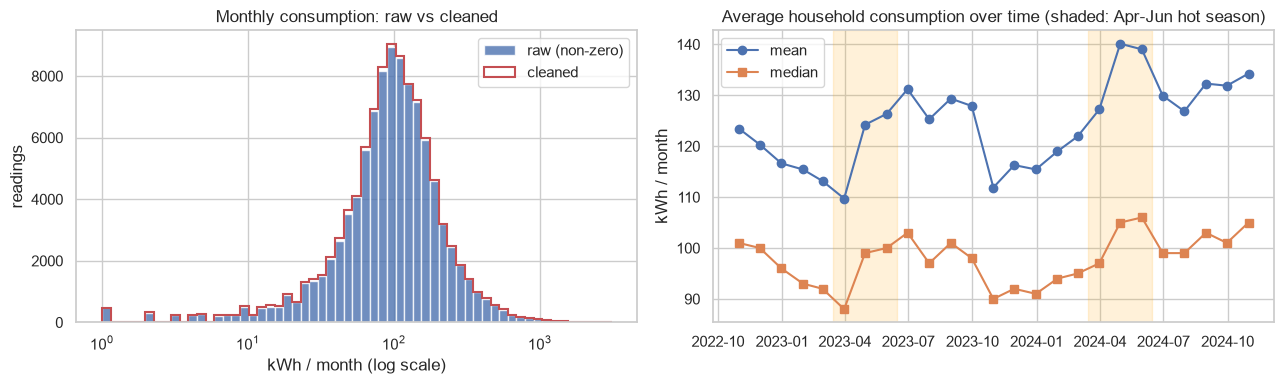

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.logspace(0, np.log10(3100), 60)
axes[0].hist(parsed[parsed > 0], bins=bins, color="#4C72B0", alpha=0.8, label="raw (non-zero)")
axes[0].hist(df["consumption"], bins=bins, histtype="step", color="#C44E52", lw=1.5, label="cleaned")
axes[0].set_xscale("log"); axes[0].set_xlabel("kWh / month (log scale)"); axes[0].set_ylabel("readings")
axes[0].set_title("Monthly consumption: raw vs cleaned"); axes[0].legend()

monthly = df.groupby("month")["consumption"].agg(["mean", "median"])
axes[1].plot(monthly.index, monthly["mean"], marker="o", label="mean")
axes[1].plot(monthly.index, monthly["median"], marker="s", label="median")
for yr in (2023, 2024):
    axes[1].axvspan(pd.Timestamp(f"{yr}-03-15"), pd.Timestamp(f"{yr}-06-15"), color="orange", alpha=0.15)
axes[1].set_title("Average household consumption over time (shaded: Apr-Jun hot season)")
axes[1].set_ylabel("kWh / month"); axes[1].legend()
plt.tight_layout(); savefig("01_distribution_and_seasonality.png")

## Step 3 — Feature engineering (no leakage)

Each row is one *(household, target month)*. **Lags are counted back from the target month**: `lag_1` is the most recent known reading and `lag_12` is the same calendar month last year, which is also exactly the seasonal-naive forecast.

| Feature | Definition (all from months strictly before the target) |
|---|---|
| `lag_1, lag_2, lag_3, lag_6, lag_12` | reading k months before the target |
| `roll_mean_3/6`, `roll_std_3/6` | mean / std of the last 3 or 6 known months |
| `hh_mean_past` | expanding mean of all of the household's past months |
| `month_of_year`, `month_sin`, `month_cos` | calendar month of the **target**; sin/cos make December and January neighbours |

Target = the (cleaned) reading of the target month. The first target month is 2023-04, the first month with a complete `lag_6` and 6-month window. `lag_12` is NaN for targets before 2023-10. These rows are kept and `lag_12` is left as NaN rather than imputed: every model that uses it is a tree ensemble with native missing-value handling (LightGBM, XGBoost and scikit-learn's Random Forest learn which branch missing rows go to; CatBoost treats them as smaller than any value), which affects 46% of training rows (37.5% of the train + validation rows the final model is fitted on), while every test row and every app forecast has a real `lag_12`.

The cell after the feature build *asserts* the absence of leakage instead of just claiming it.


In [9]:
feats = build_features(df)
print("Feature matrix:", feats.shape, "| target months", feats["month"].min().date(), "->", feats["month"].max().date())
feats[["household_ID", "month"] + FEATURES + ["target"]].head(8)

Feature matrix: (75981, 19) | target months 2023-04-30 -> 2024-10-31


,household_ID,month,lag_1,lag_2,lag_3,lag_6,lag_12,roll_mean_3,roll_mean_6,roll_std_3,roll_std_6,hh_mean_past,month_of_year,month_sin,month_cos,target
0,ID0001,2023-04-30,97.0,115.0,102.0,116.0,NaN,104.666667,113.166667,9.291573,11.788412,113.166667,4,8.660254e-01,-5.000000e-01,94.0
1,ID0001,2023-05-31,94.0,97.0,115.0,120.0,NaN,102.000000,109.500000,11.357817,13.953494,110.428571,5,5.000000e-01,-8.660254e-01,98.0
2,ID0001,2023-06-30,98.0,94.0,97.0,129.0,NaN,96.333333,105.833333,2.081666,13.526517,108.875000,6,1.224647e-16,-1.000000e+00,87.0
3,ID0001,2023-07-31,87.0,98.0,94.0,102.0,NaN,93.000000,98.833333,5.567764,9.368387,106.444444,7,-5.000000e-01,-8.660254e-01,109.0
4,ID0001,2023-08-31,109.0,87.0,98.0,115.0,NaN,98.000000,100.000000,11.000000,10.237187,106.700000,8,-8.660254e-01,-5.000000e-01,100.0
5,ID0001,2023-09-30,100.0,109.0,87.0,97.0,NaN,98.666667,97.500000,11.060440,7.231874,106.090909,9,-1.000000e+00,-1.836970e-16,101.0
6,ID0001,2023-10-31,101.0,100.0,109.0,94.0,116.0,103.333333,98.166667,4.932883,7.359801,105.666667,10,-8.660254e-01,5.000000e-01,93.0
7,ID0001,2023-11-30,93.0,101.0,100.0,98.0,120.0,98.000000,98.000000,4.358899,7.483315,104.692308,11,-5.000000e-01,8.660254e-01,85.0


In [10]:
# Leakage checks ----------------------------------------------------------------
# 1) every lag equals the household's reading exactly k months before the target month
piv = df.pivot(index="household_ID", columns="month", values="consumption")
cols = list(piv.columns)
sample = feats.sample(3000, random_state=config.SEED)
for k in config.LAGS:
    expected = [piv.at[h, cols[cols.index(m) - k]] if cols.index(m) >= k else np.nan
                for h, m in zip(sample["household_ID"], sample["month"])]
    assert np.allclose(sample[f"lag_{k}"], expected, equal_nan=True), k
# 2) rolling/expanding features never include the target month
r = sample.iloc[0]
hist = piv.loc[r.household_ID]; hist = hist[hist.index < r.month]
assert np.isclose(r.roll_mean_3, hist.iloc[-3:].mean()) and np.isclose(r.hh_mean_past, hist.mean())
# 3) the app's single-row feature path reproduces the training features exactly
row = feats[feats["month"] == feats["month"].max()].iloc[[0]]
h = piv.loc[row.household_ID.iloc[0]]; h = h[h.index < row.month.iloc[0]]
assert np.allclose(features_for_next_month(h, row.month.iloc[0]).values, row[FEATURES].values, equal_nan=True)
print("All leakage checks passed.")
feats[FEATURES + ["target"]].corr()["target"].drop("target").sort_values(ascending=False).round(3).to_frame("corr with target")

All leakage checks passed.


,corr with target
roll_mean_3,0.942
lag_1,0.940
roll_mean_6,0.935
hh_mean_past,0.927
lag_2,0.920
lag_3,0.900
lag_6,0.872
lag_12,0.861
roll_std_6,0.628
roll_std_3,0.544


## Step 4 — Time-based split

Splits are made on the **target month**, never shuffled. Every household appears in all three periods, which is realistic: CEB forecasts the *same* customers forward in time.

* Validation is used for all choices: outlier method, target formulation, hyperparameters, early-stopping rounds, Ridge alpha and the main model.
* After the choices are made, models are refit on train + validation and the **test set is scored once**.
* Fitting uses the cleaned target; **every metric is computed against the real meter reading** (not spike-clipped).


In [11]:
# Rows whose target month was itself imputed are excluded from training AND evaluation:
# we only learn from / score against real meter readings.
data = feats[~feats["target_imputed"]].reset_index(drop=True)
is_train = data["month"] <= config.TRAIN_END
is_val = (data["month"] > config.TRAIN_END) & (data["month"] <= config.VAL_END)
is_test = data["month"] > config.VAL_END
is_trval = is_train | is_val

split_info = {}
for name, m in [("train", is_train), ("validation", is_val), ("test", is_test)]:
    split_info[name] = {"target_months": f"{data.loc[m, 'month'].min():%Y-%m} -> {data.loc[m, 'month'].max():%Y-%m}",
                        "n_months": int(data.loc[m, "month"].nunique()), "rows": int(m.sum()),
                        "households": int(data.loc[m, "household_ID"].nunique())}
    print(f"{name:10s} {split_info[name]['target_months']}  ({split_info[name]['n_months']} months, {m.sum():,} rows)")
print(f"\nExcluded rows with imputed target: {int(feats['target_imputed'].sum())}")
print(f"lag_12 is missing for {data.loc[is_train, 'lag_12'].isna().mean():.0%} of training rows "
      "(target months before 2023-10); tree models handle NaN natively.")
assert data.loc[is_train, "month"].max() < data.loc[is_val, "month"].min() < data.loc[is_test, "month"].min()

X = data[FEATURES]
y_fit = data["target"]            # cleaned (spike-clipped) target used for fitting
y_true = data["target_actual"]    # real reading used for every reported metric
X_tr, y_tr = X[is_train], y_fit[is_train]
X_val, y_val_fit, y_val = X[is_val], y_fit[is_val], y_true[is_val]
X_trval, y_trval = X[is_trval].reset_index(drop=True), y_fit[is_trval].reset_index(drop=True)
X_te, y_te = X[is_test], y_true[is_test]

train      2023-04 -> 2024-04  (13 months, 51,217 rows)
validation 2024-05 -> 2024-07  (3 months, 11,827 rows)
test       2024-08 -> 2024-10  (3 months, 11,790 rows)

Excluded rows with imputed target: 1147
lag_12 is missing for 46% of training rows (target months before 2023-10); tree models handle NaN natively.


## Step 5 — Models

### 5a. Naive baselines
* **Naive:** next month = last month (`lag_1`).
* **Seasonal naive:** next month = the same month last year (`lag_12`).

These are the bar any model must clear. With monthly household data, persistence is a strong forecaster.


In [12]:
val_preds, test_preds = {}, {}
val_preds["Naive (last month)"] = X_val["lag_1"].values
test_preds["Naive (last month)"] = X_te["lag_1"].values
val_preds["Seasonal naive (same month last year)"] = X_val["lag_12"].values
test_preds["Seasonal naive (same month last year)"] = X_te["lag_12"].values
assert not np.isnan(test_preds["Seasonal naive (same month last year)"]).any()
pd.DataFrame({k: regression_metrics(y_val, v) for k, v in val_preds.items()}).T.round(3)

,RMSE,MAE,R2,MAPE_%,n
Naive (last month),45.181,20.913,0.881,18.609,11827.0
Seasonal naive (same month last year),64.037,34.645,0.762,34.326,11827.0


### 5b. Tree models: hyperparameters and search

**Target formulation: level vs. change.** A model can predict the next month's kWh directly (*level*) or predict the *change* from last month and add `lag_1` back. Tree ensembles cannot extrapolate beyond the target values seen in training, and here persistence explains most of the variance. With the change target, the naive forecast is built in, and the trees only have to learn *adjustments* to it (seasonal moves, mean reversion after unusual months). Both formulations are tuned for every model and the choice is made on validation (table below). The change target is adopted for all models, rather than picking per model, to avoid extra researcher degrees of freedom.

**Common, fixed choices (with reasons):**
* **Loss:** squared error on the kWh scale, because RMSE is the headline metric and CEB needs unbiased *totals*. A log-target model would forecast the median and under-predict the sum.
* **Boosters (XGBoost, LightGBM, CatBoost):** `learning_rate = 0.05`, a standard "small step" that trades training time for smoother convergence. The **number of trees is not guessed**: up to 3,000 rounds with early stopping (patience 100) on the validation set, and the best round count is reused when refitting on train + validation.
* **Row/column subsampling 0.8** (XGBoost, LightGBM): with only 13 highly correlated features (the lags and rolling means overlap), subsampling decorrelates trees and acts as regularisation.
* **Random Forest:** 300 trees. RF does not overfit with more trees, and the out-of-sample error plateaus well before 300 on 13 features. `bootstrap=True` is used.
* `random_state = 42` everywhere, for reproducibility.

**Searched on validation (grid, documented in `results/tuning_*.csv`):**

| Model | Grid | Why these knobs |
|---|---|---|
| Random Forest | `max_depth` ∈ {12, None} × `min_samples_leaf` ∈ {10, 40} × `max_features` ∈ {0.4, 0.7} | depth/leaf size control variance on a noisy target; `max_features` controls tree decorrelation |
| XGBoost | `max_depth` ∈ {4, 6, 8} × `min_child_weight` ∈ {5, 20} × `reg_lambda` ∈ {1, 10} | depth = interaction order; child weight and L2 regularisation guard against fitting individual noisy households |
| LightGBM | `num_leaves` ∈ {15, 31, 63} × `min_child_samples` ∈ {20, 100} × `reg_lambda` ∈ {0, 10} | LightGBM grows leaf-wise, so `num_leaves` (not depth) is its capacity knob; `min_child_samples` stops tiny leaves |
| CatBoost | `depth` ∈ {4, 6, 8} × `l2_leaf_reg` ∈ {3, 10} | symmetric trees: depth is the capacity knob, L2 is its main regulariser |

The grids are deliberately **similar in size for baselines and new models** (6–12 configurations each), so any advantage of the proposed models is not just a bigger tuning budget.


In [13]:
# Each model is tuned twice: predicting the LEVEL (kWh) and predicting the CHANGE from last month.
# The formulation is a modelling choice, so it is also decided on validation.
TARGET = "change"
best, best_level, tuning_logs, formulation_rows = {}, {}, {}, []
for name in ["RandomForest", "XGBoost", "LightGBM", "CatBoost"]:
    for target in ["level", "change"]:
        t0 = time.time()
        params, rounds, log = M.tune(name, X_tr, y_tr, X_val, y_val, y_val_fit, target=target)
        vp = M.fit_final(name, params, rounds, X_tr, y_tr, target).predict(X_val)
        formulation_rows.append({"model": name, "target": target, **regression_metrics(y_val, vp)})
        log.to_csv(config.RESULTS_DIR / f"tuning_{name}_{target}.csv", index=False)
        if target == TARGET:
            best[name], tuning_logs[name], val_preds[name] = (params, rounds), log, vp
        else:
            best_level[name] = (params, rounds)
        print(f"{name:12s} {target:6s} {len(log):2d} configs {time.time() - t0:4.0f}s | best {params} "
              f"rounds={rounds} | val RMSE {log['val_RMSE'].iloc[0]:.2f} (worst {log['val_RMSE'].iloc[-1]:.2f})")

RandomForest level   8 configs   42s | best {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 10, 'max_features': 0.7} rounds=None | val RMSE 41.38 (worst 42.33)


RandomForest change  8 configs   57s | best {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 10, 'max_features': 0.7} rounds=None | val RMSE 41.49 (worst 42.34)


XGBoost      level  12 configs    4s | best {'max_depth': 4, 'min_child_weight': 5, 'reg_lambda': 1.0} rounds=47 | val RMSE 43.98 (worst 44.96)


XGBoost      change 12 configs    5s | best {'max_depth': 4, 'min_child_weight': 20, 'reg_lambda': 10.0} rounds=125 | val RMSE 42.08 (worst 43.29)


LightGBM     level  12 configs   10s | best {'num_leaves': 63, 'min_child_samples': 20, 'reg_lambda': 10.0} rounds=58 | val RMSE 41.75 (worst 44.90)


LightGBM     change 12 configs   11s | best {'num_leaves': 63, 'min_child_samples': 20, 'reg_lambda': 0.0} rounds=50 | val RMSE 41.82 (worst 42.29)


CatBoost     level   6 configs    2s | best {'depth': 8, 'l2_leaf_reg': 10.0} rounds=61 | val RMSE 43.44 (worst 43.79)


CatBoost     change  6 configs    5s | best {'depth': 8, 'l2_leaf_reg': 10.0} rounds=319 | val RMSE 42.23 (worst 43.18)


In [14]:
formulation = pd.DataFrame(formulation_rows).pivot(index="model", columns="target", values=["RMSE", "MAE"]).round(2)
formulation.to_csv(config.RESULTS_DIR / "target_formulation_validation.csv")
formulation

RMSE           MAE       
target       change  level change  level
model                                   
CatBoost      42.23  43.44  20.66  21.37
LightGBM      41.82  41.75  20.33  20.61
RandomForest  41.49  41.38  20.32  20.39
XGBoost       42.08  43.98  20.44  21.61

In [15]:
# Top of each search log: shows how sensitive each model is to its hyperparameters
for name, log in tuning_logs.items():
    print(f"\n{name}"); print(log.head(4).round(3).to_string(index=False))


RandomForest
 n_estimators  max_depth  min_samples_leaf  max_features best_rounds  val_RMSE  fit_seconds
          300        NaN                10           0.7        None    41.492        9.931
          300        NaN                10           0.4        None    41.595        5.877
          300       12.0                10           0.7        None    41.657        5.918
          300        NaN                40           0.7        None    41.852        7.746

XGBoost
 max_depth  min_child_weight  reg_lambda  best_rounds  val_RMSE  fit_seconds
         4                20        10.0          125    42.077        0.373
         4                20         1.0           92    42.238        0.316
         4                 5         1.0           80    42.289        0.329
         6                20        10.0           68    42.361        0.362

LightGBM
 num_leaves  min_child_samples  reg_lambda  best_rounds  val_RMSE  fit_seconds
         63                 20         0.0 

### 5c. Stacking ensemble with time-ordered out-of-fold predictions

Base learners: tuned **LightGBM, CatBoost, Random Forest**. Meta-learner: **Ridge regression**.

Ordinary K-fold stacking would let a base learner trained on *future* months produce the "out-of-fold" prediction for a past month, which is leakage. Instead, an **expanding window** is used:

1. The last 8 target months are cut into 4 blocks of 2 months.
2. For each block, the base learners are fitted on **all earlier months only** and predict that block, giving honest out-of-fold (OOF) predictions.
3. Ridge `alpha` ∈ {1, 10³, 10⁵, 10⁶, 10⁷} is chosen by forward validation over the OOF blocks (fit on blocks < k, score on block k). The grid is wide because base predictions are around 10² kWh over about 10⁴ rows, so smaller alphas barely regularise. Weights are constrained to be **non-negative** (`positive=True`, as in Breiman's stacked regression): the three base predictions are highly collinear, and an unconstrained blend gives unstable, offsetting weights (one was negative in a first run).
4. Ridge is fitted on all OOF predictions, and the base learners are refitted on all data.

The stack is fitted twice: on train only (its validation score is used for model selection) and on train + validation (used for test).


In [16]:
STACK_BASES = ["LightGBM", "CatBoost", "RandomForest"]
t0 = time.time()
# (a) stack fitted on TRAIN only (its OOF blocks lie inside train) -> validation score for selection
stack_tr = M.TimeStackingRegressor({n: best[n] for n in STACK_BASES})
stack_tr.fit(X_tr.reset_index(drop=True), y_tr.reset_index(drop=True), data.loc[is_train, "month"])
val_preds["Stacking (LGBM+CatBoost+RF -> Ridge)"] = stack_tr.predict(X_val)
# (b) stack fitted on TRAIN+VALIDATION -> test predictions
stack = M.TimeStackingRegressor({n: best[n] for n in STACK_BASES})
stack.fit(X_trval, y_trval, data.loc[is_trval, "month"])
print(f"Stacking fitted twice in {time.time() - t0:.0f}s")
print("OOF blocks (train+val stack):", [f"{a:%Y-%m}..{b:%Y-%m}" for a, b in stack.oof_blocks_])
print("Ridge alpha forward-validation RMSE:", {f"{k:g}": round(v, 3) for k, v in stack.alpha_scores_.items()},
      "-> alpha =", f"{stack.alpha_:g}")
w, b = stack.weights_
print("Meta-learner weights:", {k: round(v, 3) for k, v in w.items()}, "| sum:", round(sum(w.values()), 3),
      "| intercept:", round(b, 2))

Stacking fitted twice in 95s
OOF blocks (train+val stack): ['2023-12..2024-01', '2024-02..2024-03', '2024-04..2024-05', '2024-06..2024-07']
Ridge alpha forward-validation RMSE: {'1': 41.123, '1000': 41.123, '100000': 41.134, '1e+06': 41.005, '1e+07': 41.027} -> alpha = 1e+06
Meta-learner weights: {'LightGBM': 0.214, 'CatBoost': 0.275, 'RandomForest': 0.497} | sum: 0.987 | intercept: -1.32


In [17]:
# Final single models: refit on train+validation with the tuned hyperparameters / rounds
final_models = {}
for name, (params, rounds) in best.items():
    final_models[name] = M.fit_final(name, params, rounds, X_trval, y_trval, TARGET)
    test_preds[name] = final_models[name].predict(X_te)
# Level-target versions (not selected) are also scored, for transparency only
level_test_preds = {f"{n} (level target)": M.fit_final(n, p, r, X_trval, y_trval, "level").predict(X_te)
                    for n, (p, r) in best_level.items()}
final_models["Stacking (LGBM+CatBoost+RF -> Ridge)"] = stack
test_preds["Stacking (LGBM+CatBoost+RF -> Ridge)"] = stack.predict(X_te)

### 5d. ARIMA per household (classical time-series baseline)

ARIMA is fitted per household, so it cannot share information across households. Fitting 4,000 households with order search is slow, so a **random sample of 200 households** is used (seed 42), and *every* model is re-scored on exactly the same 200 households and months for a like-for-like comparison.

* Order (p, d, q) with p, q ∈ {0, 1, 2} and d ∈ {0, 1} is chosen by **AIC** using data up to the end of validation.
* For each test month, the model is refitted on all earlier months and forecasts one step ahead (a rolling origin, just like the ML models).
* **No seasonal component:** 22–24 monthly points cannot identify a 12-month seasonal ARIMA (that needs several full cycles).


In [18]:
rng = np.random.default_rng(config.SEED)
arima_hh = rng.choice(np.sort(data.loc[is_test, "household_ID"].unique()), size=200, replace=False)
series = {h: piv.loc[h].asfreq("ME") for h in arima_hh}
test_months = sorted(data.loc[is_test, "month"].unique())
t0 = time.time()
arima = M.arima_forecasts(series, test_months, select_end=pd.Timestamp(config.VAL_END))
print(f"ARIMA: {len(arima_hh)} households x {len(M.ARIMA_ORDERS)} candidate orders + {len(test_months)} "
      f"one-step refits each, {time.time() - t0:.0f}s")
print("Most common selected orders:", arima["order"].value_counts().head(5).to_dict())

ARIMA: 200 households x 18 candidate orders + 3 one-step refits each, 11s
Most common selected orders: {'(0, 1, 1)': 204, '(0, 1, 0)': 201, '(0, 1, 2)': 57, '(2, 1, 2)': 33, '(2, 1, 0)': 27}


## Step 6 — Evaluation

Metrics are computed on the **test months** against real readings:
* **RMSE**, the headline metric: penalises large misses, which matter most for supply planning.
* **MAE:** the typical error in kWh, as a household would experience it on the bill.
* **R²**
* **MAPE:** computed only over actuals **≥ 10 kWh**. A home that used 2 kWh (vacant for most of the month) and is forecast 40 kWh gives a 1,900% error that would dominate the average while being irrelevant for planning. 10 kWh is roughly the 5th percentile of readings.
* **Skill vs naive** = 1 − RMSE / RMSE_naive. This is the most honest single number, because persistence is strong.


In [19]:
def table(preds, y):
    t = pd.DataFrame({k: regression_metrics(y, v) for k, v in preds.items()}).T
    t["RMSE_skill_vs_naive_%"] = 100 * (1 - t["RMSE"] / t.loc["Naive (last month)", "RMSE"])
    return t.sort_values("RMSE")

val_table = table(val_preds, y_val)
test_table = table(test_preds, y_te)
val_table.round(3).to_csv(config.RESULTS_DIR / "validation_metrics.csv")
test_table.round(3).to_csv(config.RESULTS_DIR / "test_metrics.csv")
print("VALIDATION (model selection)"); print(val_table.round(3).to_string())
print("\nTEST (never used for choices)"); print(test_table.round(3).to_string())

VALIDATION (model selection)
                                         RMSE     MAE     R2  MAPE_%        n  RMSE_skill_vs_naive_%
RandomForest                           41.492  20.316  0.900  18.695  11827.0                  8.164
LightGBM                               41.821  20.335  0.898  18.757  11827.0                  7.437
XGBoost                                42.077  20.439  0.897  18.771  11827.0                  6.872
Stacking (LGBM+CatBoost+RF -> Ridge)   42.210  20.446  0.896  18.693  11827.0                  6.575
CatBoost                               42.229  20.659  0.896  19.055  11827.0                  6.534
Naive (last month)                     45.181  20.913  0.881  18.609  11827.0                  0.000
Seasonal naive (same month last year)  64.037  34.645  0.762  34.326  11827.0                -41.733

TEST (never used for choices)
                                         RMSE     MAE     R2  MAPE_%        n  RMSE_skill_vs_naive_%
Naive (last month)             

In [20]:
# Transparency: the same tree models trained on the LEVEL target (rejected on validation)
level_table = table({"Naive (last month)": test_preds["Naive (last month)"], **level_test_preds}, y_te)
level_table.round(3).to_csv(config.RESULTS_DIR / "test_metrics_level_target.csv")
print(level_table.round(3).to_string())

                               RMSE     MAE     R2  MAPE_%        n  RMSE_skill_vs_naive_%
RandomForest (level target)  45.674  20.077  0.884  16.521  11790.0                  2.152
Naive (last month)           46.678  18.644  0.879  16.216  11790.0                  0.000
CatBoost (level target)      49.805  20.879  0.862  18.634  11790.0                 -6.698
LightGBM (level target)      50.085  21.393  0.860  18.139  11790.0                 -7.298
XGBoost (level target)       51.239  21.238  0.854  20.151  11790.0                 -9.771


In [21]:
# ARIMA comparison on the SAME 200 households and months
test_rows = data.loc[is_test, ["household_ID", "month"]].reset_index(drop=True)
on_sample = test_rows["household_ID"].isin(arima_hh).values
merged = test_rows[on_sample].merge(arima, on=["household_ID", "month"], how="left")
sample_preds = {k: v[on_sample] for k, v in test_preds.items()}
sample_preds["ARIMA per household (AIC-selected)"] = merged["pred"].values
arima_table = table(sample_preds, y_te.values[on_sample])
arima_table.round(3).to_csv(config.RESULTS_DIR / "arima_sample_metrics.csv")
print(f"Test metrics on the {len(arima_hh)}-household ARIMA sample ({on_sample.sum()} rows)")
print(arima_table.round(3).to_string())

Test metrics on the 200-household ARIMA sample (595 rows)
                                         RMSE     MAE     R2  MAPE_%      n  RMSE_skill_vs_naive_%
XGBoost                                51.514  23.619  0.869  18.089  595.0                  5.068
RandomForest                           52.751  23.808  0.862  18.100  595.0                  2.788
CatBoost                               52.771  23.852  0.862  18.256  595.0                  2.752
Stacking (LGBM+CatBoost+RF -> Ridge)   53.879  24.962  0.856  18.663  595.0                  0.710
Naive (last month)                     54.264  21.989  0.854  17.384  595.0                  0.000
LightGBM                               54.520  23.564  0.853  17.724  595.0                 -0.471
ARIMA per household (AIC-selected)     59.994  22.266  0.822  17.256  595.0                -10.558
Seasonal naive (same month last year)  69.779  39.414  0.759  35.197  595.0                -28.591


In [22]:
# Main model = lowest VALIDATION RMSE among the PROPOSED models. RF and XGBoost were taught in
# lectures, so by the assignment rules they are baselines only. The test set is not used to choose.
PROPOSED = ["LightGBM", "CatBoost", "Stacking (LGBM+CatBoost+RF -> Ridge)"]
BEST_NAME = val_table.loc[PROPOSED, "RMSE"].idxmin()
print(val_table.loc[PROPOSED, ["RMSE", "MAE"]].round(3).to_string(), "\n")
best_model = final_models[BEST_NAME]
best_pred = test_preds[BEST_NAME]
print("Best model by validation RMSE:", BEST_NAME)
print(test_table.loc[BEST_NAME].round(3).to_dict())

                                        RMSE     MAE
LightGBM                              41.821  20.335
CatBoost                              42.229  20.659
Stacking (LGBM+CatBoost+RF -> Ridge)  42.210  20.446 

Best model by validation RMSE: LightGBM
{'RMSE': 48.495, 'MAE': 20.842, 'R2': 0.869, 'MAPE_%': 16.558, 'n': 11790.0, 'RMSE_skill_vs_naive_%': -3.892}


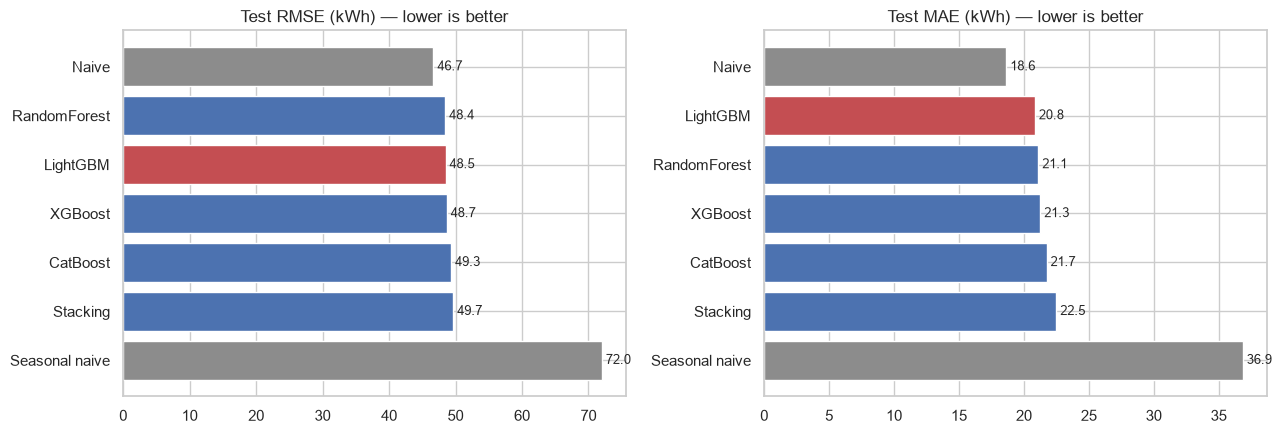

In [23]:
short = {k: k.split(" (")[0] for k in test_table.index}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ["RMSE", "MAE"]):
    t = test_table[metric].rename(short).sort_values()
    colors = ["#C44E52" if k == short[BEST_NAME] else ("#8C8C8C" if "aive" in k else "#4C72B0") for k in t.index]
    ax.barh(t.index, t.values, color=colors)
    for i, v in enumerate(t.values):
        ax.text(v, i, f" {v:.1f}", va="center", fontsize=9)
    ax.set_title(f"Test {metric} (kWh) — lower is better"); ax.invert_yaxis()
plt.tight_layout(); savefig("02_model_comparison.png")

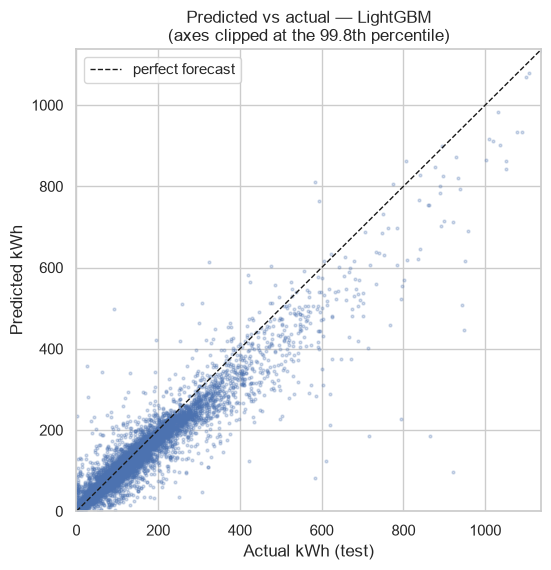

In [24]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_te, best_pred, s=4, alpha=0.25)
lim = [0, np.percentile(np.r_[y_te, best_pred], 99.8)]
ax.plot(lim, lim, "k--", lw=1, label="perfect forecast")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Actual kWh (test)"); ax.set_ylabel("Predicted kWh")
ax.set_title(f"Predicted vs actual — {short[BEST_NAME]}\n(axes clipped at the 99.8th percentile)")
ax.legend(); savefig("03_predicted_vs_actual.png")

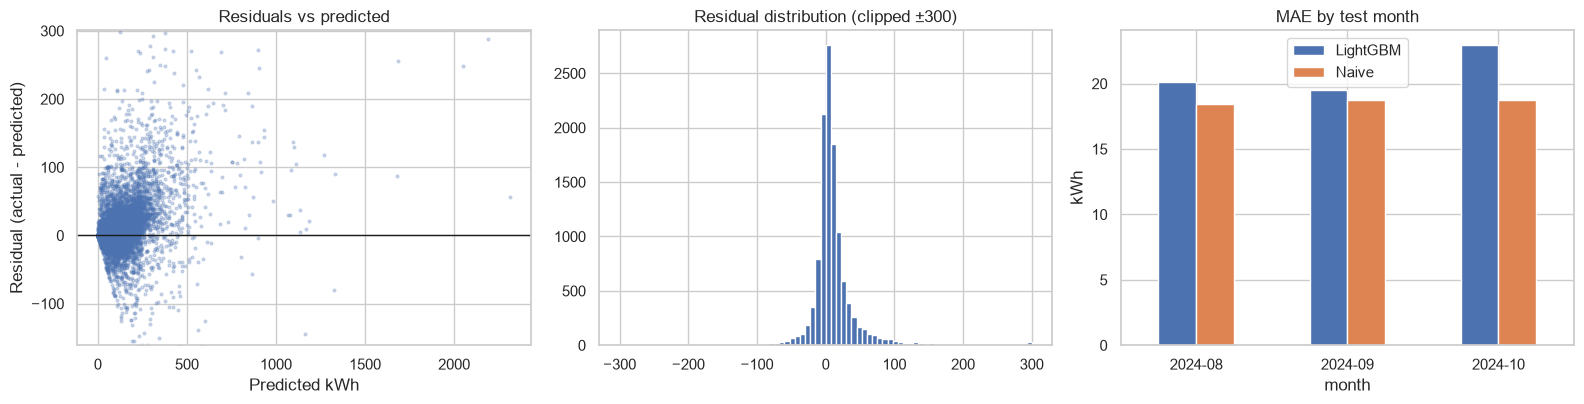

Mean residual (bias): 11.21 kWh | median: 5.12 kWh


In [25]:
resid = y_te.values - best_pred
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].scatter(best_pred, resid, s=4, alpha=0.25); axes[0].axhline(0, color="k", lw=1)
axes[0].set_xlabel("Predicted kWh"); axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title("Residuals vs predicted"); axes[0].set_ylim(np.percentile(resid, [0.2, 99.8]))
axes[1].hist(np.clip(resid, -300, 300), bins=80, color="#4C72B0"); axes[1].set_title("Residual distribution (clipped ±300)")
by_month = pd.DataFrame({"month": data.loc[is_test, "month"].dt.strftime("%Y-%m").values, "abs": np.abs(resid),
                         "naive": np.abs(y_te.values - X_te["lag_1"].values)}).groupby("month").mean()
by_month.rename(columns={"abs": short[BEST_NAME], "naive": "Naive"}).plot.bar(ax=axes[2], rot=0)
axes[2].set_title("MAE by test month"); axes[2].set_ylabel("kWh")
plt.tight_layout(); savefig("04_residuals.png")
print(f"Mean residual (bias): {resid.mean():.2f} kWh | median: {np.median(resid):.2f} kWh")

### Sanity check: are the scores suspiciously high?

**No, and the real risk turned out to be the opposite.**

* **No leakage found.** The feature cell *asserts* that every lag equals the reading k months before the target, that rolling and expanding windows end before the target month, and that the app's feature path reproduces training exactly. Cleaning statistics come from training months only, and test rows are scored against real, unclipped readings.
* **R² ≈ 0.87–0.90 looks high but is not evidence of skill.** Naive already reaches R² = 0.88, because most of the variance is *between* households (a 600 kWh household stays a 600 kWh household). The honest measure is **skill vs naive**, and the within-household R² below.
* **Validation gains did not transfer to test.** On validation every learned model beats naive by 6.5–8% RMSE; on the three test months every one is 4–6% worse. Test MAE is also worse than naive.
* **The errors are biased in opposite directions in the two periods.** The models over-predict validation slightly (−3 kWh mean residual) and under-predict test (+11 kWh). The chart below shows that every month carries a change shared by all households (e.g. −16 kWh in Oct 2023, +13 kWh in Apr 2024). A model that sees only each household's own history cannot know next month's shared change.

Three test months are too few to rank models reliably, so a rolling-origin backtest over nine months follows.


R2 (overall):            naive 0.879 | LightGBM 0.869
R2 (within household):   naive -1.017 | LightGBM -0.576


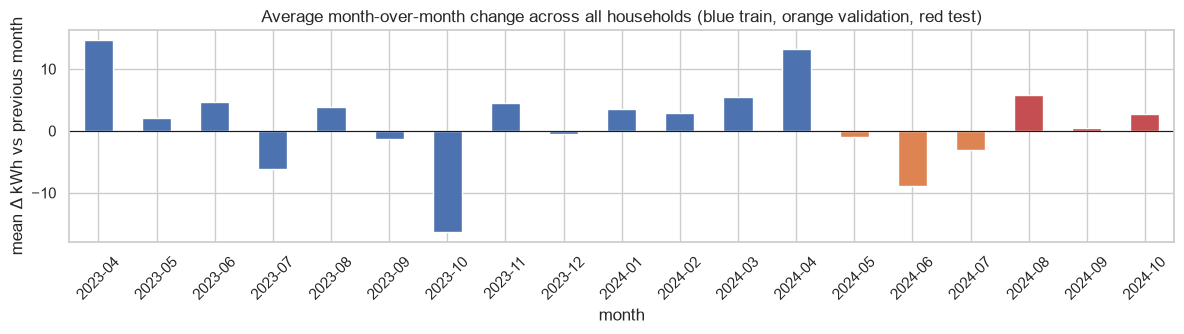

Mean residual on validation (train-only model): -3.35 kWh, on test: +11.21 kWh


In [26]:
# Suspicious-score check: how much of R2 is just "big households stay big"?
def within_r2(pred):
    d = data.loc[is_test, ["household_ID"]].assign(y=y_te.values, p=pred)
    d[["y", "p"]] -= d.groupby("household_ID")[["y", "p"]].transform("mean")
    return 1 - ((d.y - d.p) ** 2).sum() / (d.y ** 2).sum()

print(f"R2 (overall):            naive {test_table.loc['Naive (last month)', 'R2']:.3f} | "
      f"{short[BEST_NAME]} {test_table.loc[BEST_NAME, 'R2']:.3f}")
print(f"R2 (within household):   naive {within_r2(X_te['lag_1'].values):.3f} | {short[BEST_NAME]} {within_r2(best_pred):.3f}")

# Common shocks: average month-over-month change shared by ALL households, per target month
shock = data.groupby(data["month"].dt.strftime("%Y-%m")).apply(lambda g: (g["target_actual"] - g["lag_1"]).mean())
ax = shock.plot.bar(figsize=(12, 3.5), color=["#C44E52" if m > config.VAL_END[:7] else
                                               ("#DD8452" if m > config.TRAIN_END[:7] else "#4C72B0") for m in shock.index])
ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("mean Δ kWh vs previous month")
ax.set_title("Average month-over-month change across all households (blue train, orange validation, red test)")
plt.xticks(rotation=45); plt.tight_layout(); savefig("10_common_monthly_shocks.png")
print(f"Mean residual on validation (train-only model): {np.mean(y_val - val_preds[BEST_NAME]):+.2f} kWh, "
      f"on test: {np.mean(y_te - best_pred):+.2f} kWh")

### Robustness check: rolling-origin backtest (9 forecast months)

The test set holds only 3 target months, and the analysis above shows that each month's error is dominated by a **shock shared by all households**. Three months therefore give only about three independent draws, which is too few to rank models reliably.

As a robustness check, a **rolling-origin (expanding-window) backtest** is run for every target month from 2024-02 to 2024-10. For each month *m*, every model is refitted on all target months before *m* and forecasts *m*, exactly as it would be used operationally. Naive is scored on the same rows.

Caveats, stated up front:
* Hyperparameters and boosting rounds are **fixed at the values tuned on validation** (retuning per origin would multiply the cost about 10×). May–Jul 2024 were used for that tuning, so scores for those months are slightly optimistic.
* Cleaning statistics (household medians, spike limits) were fitted on months ≤ 2024-04. For the earliest origins they include a few later months, a small, conservative leak that affects only imputed/clipped values (about 2% of readings).

This check is reported **alongside** the test results; it is not used to choose the model.


In [27]:
BT_ORIGINS = pd.date_range("2024-02-29", "2024-10-31", freq="ME")
t0 = time.time()
bt = M.rolling_backtest(X, y_fit, y_true, data["month"], BT_ORIGINS, best, stack_bases=STACK_BASES, target=TARGET)
bt["model"] = bt["model"].replace({"Stacking": "Stacking (LGBM+CatBoost+RF -> Ridge)"})
naive_bt = bt[bt["model"] == "Naive (last month)"].set_index("month")
bt["RMSE_skill_%"] = 100 * (1 - bt["RMSE"] / bt["month"].map(naive_bt["RMSE"]))
bt["MAE_skill_%"] = 100 * (1 - bt["MAE"] / bt["month"].map(naive_bt["MAE"]))
bt.round(3).to_csv(config.RESULTS_DIR / "backtest_by_month.csv", index=False)
print(f"Rolling-origin backtest: {len(BT_ORIGINS)} origins x {bt['model'].nunique()} models "
      f"in {(time.time() - t0) / 60:.1f} min\n")

bt_summary = (bt[bt["model"] != "Naive (last month)"].groupby("model")
              .agg(mean_RMSE=("RMSE", "mean"), mean_MAE=("MAE", "mean"),
                   mean_RMSE_skill_pct=("RMSE_skill_%", "mean"), mean_MAE_skill_pct=("MAE_skill_%", "mean"),
                   months_beating_naive_RMSE=("RMSE_skill_%", lambda s: int((s > 0).sum())),
                   months_beating_naive_MAE=("MAE_skill_%", lambda s: int((s > 0).sum())))
              .sort_values("mean_RMSE"))
bt_summary.loc["Naive (last month)", ["mean_RMSE", "mean_MAE"]] = naive_bt[["RMSE", "MAE"]].mean().values
bt_summary.round(2).to_csv(config.RESULTS_DIR / "backtest_summary.csv")
print(f"Months beating naive are counted out of {len(BT_ORIGINS)}.")
bt_summary.round(2)

Rolling-origin backtest: 9 origins x 6 models in 9.7 min

Months beating naive are counted out of 9.


,mean_RMSE,mean_MAE,mean_RMSE_skill_pct,mean_MAE_skill_pct,months_beating_naive_RMSE,months_beating_naive_MAE
model,,,,,,
RandomForest,42.92,20.21,3.93,-2.05,6.0,6.0
Stacking (LGBM+CatBoost+RF -> Ridge),43.32,20.13,3.08,-1.57,6.0,5.0
XGBoost,43.34,20.23,3.04,-2.10,7.0,6.0
LightGBM,43.44,20.16,2.83,-1.72,6.0,6.0
CatBoost,43.70,20.59,2.05,-4.13,5.0,6.0
Naive (last month),44.68,19.90,NaN,NaN,NaN,NaN


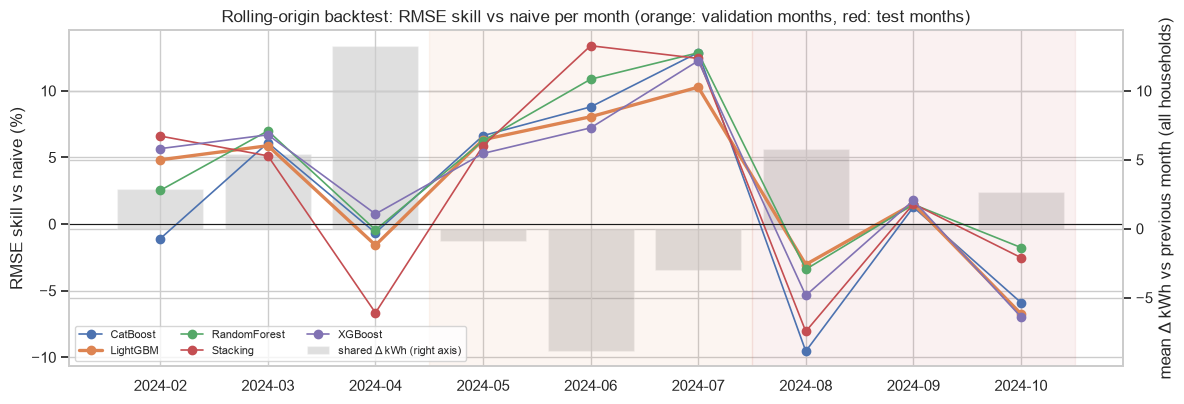

Correlation between monthly RMSE skill and |shared shock|: {'CatBoost': -0.06, 'LightGBM': -0.13, 'RandomForest': -0.07, 'Stacking': -0.26, 'XGBoost': -0.06}


In [28]:
skill = bt.pivot(index="month", columns="model", values="RMSE_skill_%").drop(columns="Naive (last month)")
skill.index = skill.index.strftime("%Y-%m")
fig, ax = plt.subplots(figsize=(12, 4.2))
ax2 = ax.twinx()
ax2.bar(skill.index, shock.reindex(skill.index).values, color="grey", alpha=0.25, label="shared Δ kWh (right axis)")
ax2.set_ylabel("mean Δ kWh vs previous month (all households)")
for col in skill.columns:
    ax.plot(skill.index, skill[col], marker="o", lw=2.4 if col == BEST_NAME else 1.2, label=short.get(col, col))
ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("RMSE skill vs naive (%)")
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.axvspan(2.5, 5.5, color="#DD8452", alpha=0.08); ax.axvspan(5.5, 8.5, color="#C44E52", alpha=0.08)
ax.set_title("Rolling-origin backtest: RMSE skill vs naive per month (orange: validation months, red: test months)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, ncol=3, loc="lower left")
plt.tight_layout(); savefig("11_backtest_skill_by_month.png")

# Is skill related to the size of the shared monthly shock?
abs_shock = shock.reindex(skill.index).abs()
print("Correlation between monthly RMSE skill and |shared shock|:",
      {short.get(c, c): round(float(np.corrcoef(skill[c], abs_shock)[0, 1]), 2) for c in skill.columns})

## Step 7 — Explainability

SHAP (TreeSHAP) explains each prediction as a base value plus one additive contribution per feature, in kWh. If the best model is the stack, its SHAP values are obtained **exactly** as the Ridge-weighted sum of the base learners' SHAP values, because the meta-learner is linear.

**How SHAP is computed for the change target, and why it matters.** The tree model predicts the *change* from last month, f(x). The deployed model is g(x) = `lag_1` + f(x), and the plots explain g, i.e. the **level** in kWh (so a waterfall starts at the average forecast, ≈ 126 kWh, not at an average change). Because SHAP is additive, g's attribution is f's TreeSHAP values plus the exact SHAP value of the linear term, `lag_1 − mean(lag_1)`, which is added to `lag_1` (see `src/explain.py`). **Consequence: a large part of `lag_1`'s importance is built in by the model design, not learned from the data.** The cell after the importance table separates the two parts.

SHAP for 1000 test rows in 0s
Additivity check (max |base + sum(SHAP) - prediction|): 0.0


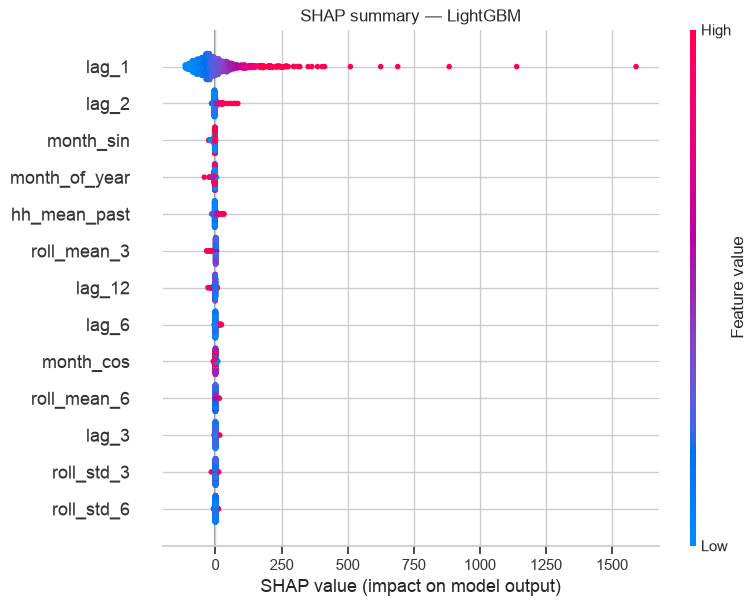

In [29]:
X_shap = X_te.sample(1000, random_state=config.SEED)
t0 = time.time()
sv = explain(best_model, X_shap)
print(f"SHAP for {len(X_shap)} test rows in {time.time() - t0:.0f}s")
recon = sv.base_values + sv.values.sum(1)
print("Additivity check (max |base + sum(SHAP) - prediction|):",
      round(float(np.abs(recon - best_model.predict(X_shap)).max()), 4))

shap.plots.beeswarm(sv, max_display=13, show=False)
plt.title(f"SHAP summary — {short[BEST_NAME]}"); savefig("05_shap_beeswarm.png")

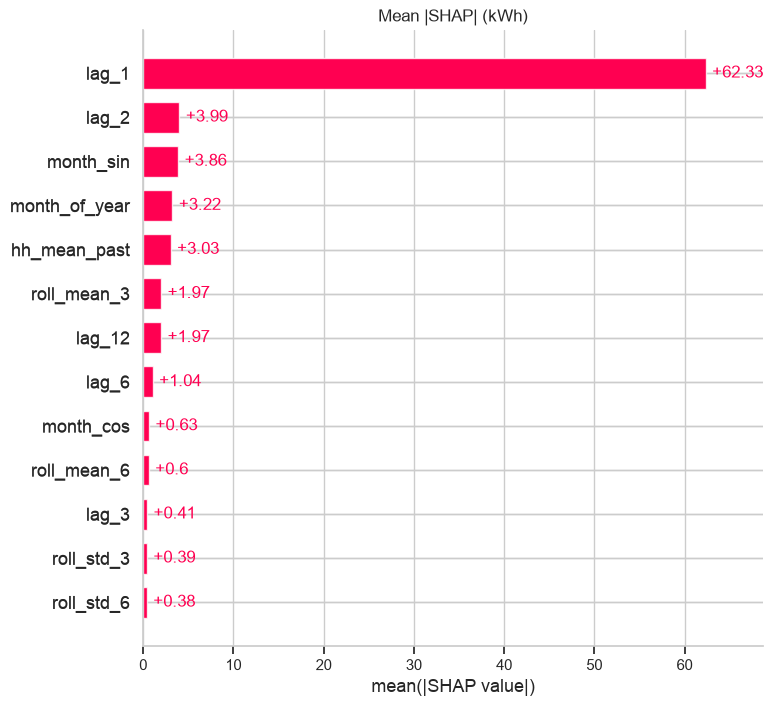

,mean |SHAP| kWh
lag_1,62.33
lag_2,3.99
month_sin,3.86
month_of_year,3.22
hh_mean_past,3.03
roll_mean_3,1.97
lag_12,1.97
lag_6,1.04
month_cos,0.63
roll_mean_6,0.60


In [30]:
shap.plots.bar(sv, max_display=13, show=False)
plt.title("Mean |SHAP| (kWh)"); savefig("06_shap_bar.png")
importance = pd.Series(np.abs(sv.values).mean(0), index=FEATURES).sort_values(ascending=False)
importance.round(2).to_frame("mean |SHAP| kWh")

In [31]:
# Separate lag_1's SHAP into the part fixed by design (the identity term lag_1 - mean(lag_1))
# and the part the trees actually learned. Only meaningful for the change-target wrapper.
if isinstance(best_model, M.ChangeTargetRegressor):
    j = FEATURES.index("lag_1")
    by_design = X_shap["lag_1"].values - best_model.base_mean_
    learned = sv.values[:, j] - by_design
    print(f"lag_1 mean |SHAP|: total {np.abs(sv.values[:, j]).mean():.1f} kWh; "
          f"by-design term alone {np.abs(by_design).mean():.1f}; learned part {np.abs(learned).mean():.1f}")
    print(f"corr(by design, learned) = {np.corrcoef(by_design, learned)[0, 1]:.2f}  "
          "(negative = the trees pull extreme households back towards the average)")
    q = pd.qcut(X_shap["lag_1"], [0, .5, .9, 1], labels=["bottom 50%", "50-90%", "top 10%"])
    display(pd.Series(learned, index=X_shap.index).groupby(q, observed=True).mean().round(1)
            .to_frame("mean learned lag_1 SHAP (kWh), by lag_1 band").T)
    learned_imp = importance.copy()
    learned_imp["lag_1"] = np.abs(learned).mean()
    display(learned_imp.sort_values(ascending=False).round(2).to_frame("mean |SHAP| kWh, learned part only"))

lag_1 mean |SHAP|: total 62.3 kWh; by-design term alone 72.3; learned part 10.5
corr(by design, learned) = -0.96  (negative = the trees pull extreme households back towards the average)


lag_1,bottom 50%,50-90%,top 10%
"mean learned lag_1 SHAP (kWh), by lag_1 band",9.0,-0.2,-43.9


,"mean |SHAP| kWh, learned part only"
lag_1,10.49
lag_2,3.99
month_sin,3.86
month_of_year,3.22
hh_mean_past,3.03
roll_mean_3,1.97
lag_12,1.97
lag_6,1.04
month_cos,0.63
roll_mean_6,0.60


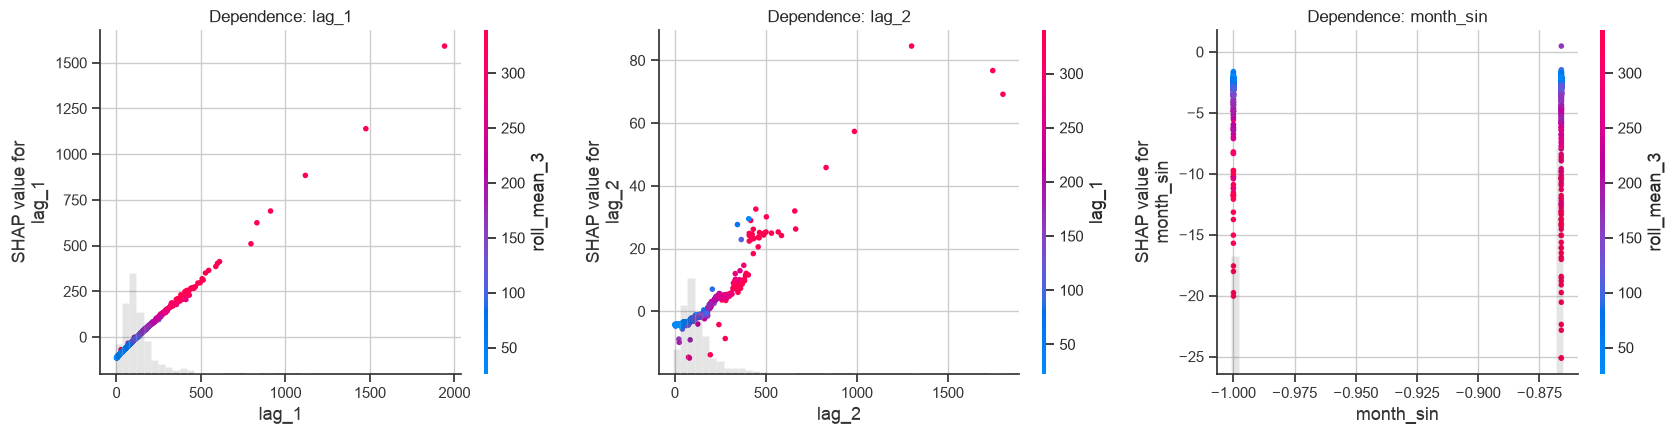

In [32]:
top3 = importance.index[:3].tolist()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, f in zip(axes, top3):
    shap.plots.scatter(sv[:, f], color=sv, ax=ax, show=False)
    ax.set_title(f"Dependence: {f}")
plt.tight_layout(); savefig("07_shap_dependence_top3.png")

Household ID1080, target month 2024-10: predicted 98.1 kWh, actual 108 kWh


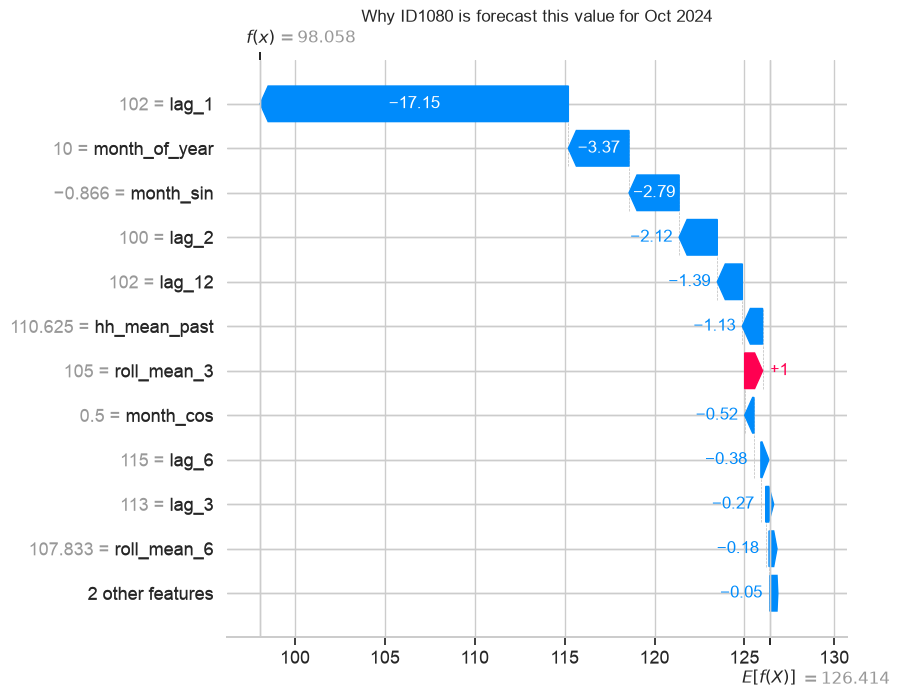

In [33]:
# Waterfall for one household's test prediction (a typical, mid-sized household)
mid = X_shap.index[np.argsort(np.abs(X_shap["lag_1"].values - X_shap["lag_1"].median()))[0]]
i = list(X_shap.index).index(mid)
hh, mon = data.loc[mid, "household_ID"], data.loc[mid, "month"]
print(f"Household {hh}, target month {mon:%Y-%m}: predicted {best_model.predict(X_shap.loc[[mid]])[0]:.1f} kWh, "
      f"actual {data.loc[mid, 'target_actual']:.0f} kWh")
shap.plots.waterfall(sv[i], max_display=12, show=False)
plt.title(f"Why {hh} is forecast this value for {mon:%b %Y}"); savefig("08_shap_waterfall_example.png")

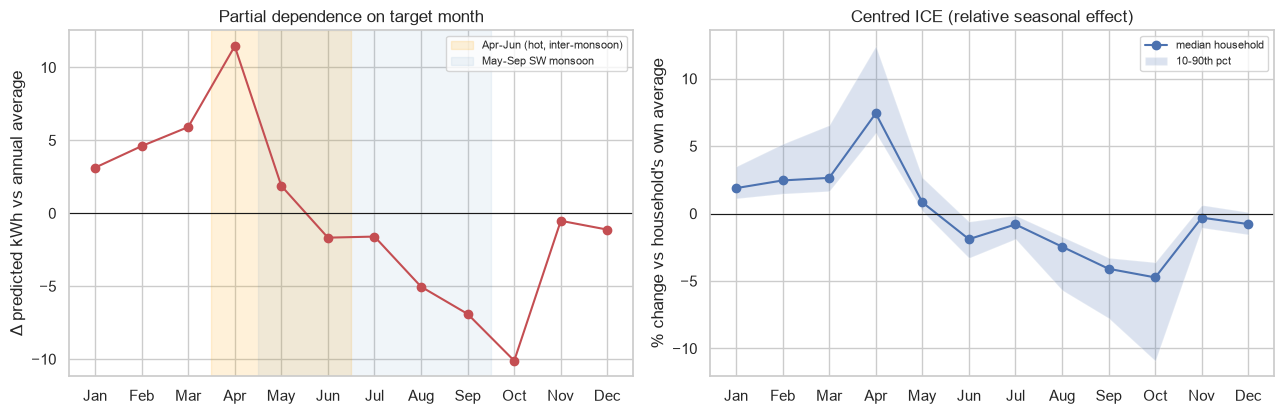

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
PDP Δ kWh,3.12,4.6,5.91,11.45,1.88,-1.67,-1.6,-5.04,-6.91,-10.11,-0.52,-1.12


In [34]:
# Partial dependence of month-of-year. month_of_year, month_sin and month_cos describe the SAME
# calendar month, so they are changed together (a library PDP on one column would create
# impossible combinations such as month=5 with the sin/cos of December).
pdp_X = X_te.sample(2000, random_state=config.SEED)
ice = []
for m in range(1, 13):
    Xm = pdp_X.assign(month_of_year=m, month_sin=np.sin(2 * np.pi * m / 12), month_cos=np.cos(2 * np.pi * m / 12))
    ice.append(best_model.predict(Xm))
ice = np.array(ice)                     # 12 x n
pdp = ice.mean(1)
centered = ice - ice.mean(0)            # centred ICE: seasonal effect relative to each household's own level

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
axes[0].plot(names, pdp - pdp.mean(), marker="o", color="#C44E52")
axes[0].axvspan(2.5, 5.5, color="orange", alpha=0.15, label="Apr-Jun (hot, inter-monsoon)")
axes[0].axvspan(3.5, 8.5, color="steelblue", alpha=0.08, label="May-Sep SW monsoon")
axes[0].axhline(0, color="k", lw=0.8); axes[0].set_ylabel("Δ predicted kWh vs annual average")
axes[0].set_title("Partial dependence on target month"); axes[0].legend(fontsize=8)
pct = 100 * centered / np.maximum(ice.mean(0), 1)
axes[1].plot(names, np.percentile(pct, 50, axis=1), marker="o", label="median household")
axes[1].fill_between(range(12), np.percentile(pct, 10, axis=1), np.percentile(pct, 90, axis=1), alpha=0.2, label="10-90th pct")
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_ylabel("% change vs household's own average")
axes[1].set_title("Centred ICE (relative seasonal effect)"); axes[1].legend(fontsize=8)
plt.tight_layout(); savefig("09_pdp_month_of_year.png")
pd.Series(pdp - pdp.mean(), index=names).round(2).to_frame("PDP Δ kWh").T

In [35]:
# Cross-check the model's seasonal story against the raw data: average ratio of each
# month's reading to the household's own mean (independent of any model).
ratio = df.assign(r=df["consumption"] / df.groupby("household_ID")["consumption"].transform("mean"))
raw_season = ratio.groupby(ratio["month"].dt.month)["r"].mean().sub(1).mul(100).round(1)
raw_season.index = names
raw_season.to_frame("raw data: % vs household mean").T

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
raw data: % vs household mean,-4.5,-4.7,-5.4,5.0,5.4,3.1,0.2,3.9,3.0,0.8,-2.5,-5.0


### What the model learned

**1. "Last month, plus small corrections."** `lag_1` dominates the SHAP plots (mean |SHAP| ≈ 62 kWh) and its dependence plot is close to a straight line. **This dominance is mostly built in by design, not discovered by the model.** The forecast is `lag_1` + f(x), and the identity term `lag_1 − mean(lag_1)` is attributed to `lag_1` exactly; on its own it averages ≈ 72 kWh, *more* than the total. The part the trees actually learned for `lag_1` is ≈ 10 kWh and runs **against** the identity term (correlation −0.96): about +9 kWh for the lower half of households and about −44 kWh for the top 10%. That is **mean reversion**: a very high last month is partly a one-off, so the model does not carry it forward in full. `lag_1`'s importance should therefore be read as "persistence was assumed, and the model learned how much to discount it", not as evidence that the model discovered persistence. With the by-design part removed, `lag_1` is still the largest learned effect, but about 2.5× the next feature rather than 15×. The other learned corrections average a few kWh:
* **`lag_2` (≈ 4 kWh):** when the month before last was high relative to last month, the model adds kWh back. It has learned **partial rebound after an unusual month** (e.g. a dip from a holiday away or a short billing period).
* **`hh_mean_past` (≈ 3 kWh):** high long-run means push the forecast up. This is a pull towards the household's own normal level, the same idea.
* **Month features (`month_sin`, `month_of_year`, `month_cos`, ≈ 8 kWh combined):** the calendar effect, below.
* Volatility (`roll_std_*`) and the longer lags contribute almost nothing.

*Note:* the SHAP sample is drawn from the test months (Aug–Oct), so the `month_sin` dependence plot only shows those three months. The PDP covers the full year.

**2. Seasonality vs the Sri Lankan context.** With the change target, the month PDP shows the expected **change into** each month:
* **Rise into March–April (+6 to +11 kWh, about +7% for the median household).** This matches the raw data, where April–May readings are about 5% above each household's own average. That fits the **hottest, most humid inter-monsoon period (March–May)**, when fans, air conditioners and refrigerators work hardest.
* **Decline from June to October.** This is consistent with cooler, wetter **south-west monsoon** months reducing cooling load. The raw data only *partly* supports "monsoon months are lower": August–September are still about 3–4% above average, and the **lowest** months are actually **December–March** (about −5%). December–February is the cooler north-east monsoon season, but a low **March** is surprising for a hot month. It may reflect conditions specific to 2023–24 (e.g. tariff changes) rather than climate. This is not verified here.
* **Caveat that matters: month effects are confounded with one-off events, including tariff changes.** The final model is trained on target months 2023-04 → 2024-07: August to March appear **once** each and April to July **twice**, and each appearance is a single month shared by all 3,999 households. "Month = October" in the training data is therefore identical to "October 2023, with whatever tariff, price and weather conditions applied that month", and the model cannot separate a calendar effect from anything else that happened in that month. Sri Lanka's electricity tariffs were revised during 2023–24, so tariff changes are a plausible confounder (dates not verified here). The PDP should be read as **"the change the model associates with each month of 2023–24"**, not as a causal seasonal effect; the agreement of the March–April rise with the hot season is suggestive but cannot be confirmed with this data.
* **Example of the confounding:** the large October effect (−10 kWh) mirrors a **single** event, the −16 kWh drop shared by all households in October 2023. The model treated that one-off as seasonal and, in the backtest, predicted a drop for October 2024 that did not happen (LightGBM bias +14 kWh that month vs +3 kWh for naive). With two years of data, month features partly **memorise one-year events** rather than learn a climate pattern.


## Step 8 — Save artefacts

* `models/best_model.joblib`: model, feature list, cleaning parameters and test metrics (everything the app needs).
* `models/feature_list.json`
* `results/summary.json`: splits, cleaning log, hyperparameters and search spaces, all metrics.


In [36]:
bundle = {
    "model": best_model,
    "model_name": BEST_NAME,
    "features": FEATURES,
    "cleaning": {k: v for k, v in clean_params.items() if k != "dropped_households"},
    "trained_on_target_months": f"{data.loc[is_trval, 'month'].min():%Y-%m} -> {data.loc[is_trval, 'month'].max():%Y-%m}",
    "test_metrics": test_table.loc[BEST_NAME].to_dict(),
}
joblib.dump(bundle, config.MODELS_DIR / "best_model.joblib", compress=3)
json.dump(FEATURES, open(config.MODELS_DIR / "feature_list.json", "w"), indent=2)

def jsonable(o):
    if isinstance(o, dict): return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer, np.bool_)): o = o.item()
    if isinstance(o, float) and np.isnan(o): return None
    return o

summary = {
    "best_model": BEST_NAME,
    "selection_rule": "lowest validation RMSE among proposed (non-lecture) models: " + ", ".join(PROPOSED),
    "target_formulation": f"{TARGET} (prediction = lag_1 + model output)" if TARGET == "change" else TARGET,
    "target_formulation_validation": pd.DataFrame(formulation_rows).set_index(["model", "target"])[["RMSE", "MAE"]]
                                       .round(3).reset_index().to_dict(orient="records"),
    "splits": split_info,
    "cleaning_log": cleaning_log,
    "outlier_method_comparison": outlier_cmp.to_dict(orient="records"),
    "hyperparameters": {n: {"params": p, "n_rounds": r, **({"learning_rate": M.BOOSTER_FIXED["learning_rate"]} if r else {})}
                        for n, (p, r) in best.items()},
    "search_spaces": M.SEARCH_SPACES,
    "stacking": {"bases": STACK_BASES, "ridge_alpha": stack.alpha_, "weights": stack.weights_[0],
                 "intercept": stack.weights_[1], "oof_blocks": [f"{a:%Y-%m}..{b:%Y-%m}" for a, b in stack.oof_blocks_]},
    "validation_metrics": val_table.to_dict(orient="index"),
    "test_metrics": test_table.to_dict(orient="index"),
    "arima_sample_test_metrics": arima_table.to_dict(orient="index"),
    "test_metrics_level_target": level_table.to_dict(orient="index"),
    "rolling_backtest": {"origins": [f"{m:%Y-%m}" for m in BT_ORIGINS],
                         "summary": bt_summary.to_dict(orient="index"),
                         "note": "hyperparameters fixed from validation tuning (May-Jul 2024 lie inside the window)"},
    "shap_mean_abs": importance.to_dict(),
    "mape_rule": f"actuals < {config.MAPE_MIN_ACTUAL} kWh excluded",
}
json.dump(jsonable(summary), open(config.RESULTS_DIR / "summary.json", "w"), indent=2)
print("Saved:", sorted(p.name for p in config.MODELS_DIR.iterdir()), "+ results/summary.json")
print(f"Notebook runtime: {(time.time() - NOTEBOOK_START) / 60:.1f} min")

Saved: ['best_model.joblib', 'feature_list.json'] + results/summary.json
Notebook runtime: 14.4 min


## Conclusions and limitations

**Results.**
* **Data quality:** 57 thousands-formatted readings were recovered rather than discarded, and 2,332 zeros were treated as faults. 64 near-empty households were dropped instead of being filled with invented values. A global 99.5th-percentile cap was **rejected on evidence**: 74% of what it clips belongs to households that are heavy *every* month, and it raised validation RMSE by 38%. Household-relative spike clipping was used instead.
* **Test months (Aug–Oct 2024):** the main model, **LightGBM** (best proposed model on validation), has RMSE 48.5 kWh and MAE 20.8 kWh, which is **3.9% worse than naive** in RMSE. CatBoost and stacking are also worse than naive; ARIMA and seasonal naive are clearly worse still.
* **Rolling-origin backtest (9 months):** all learned models beat naive on RMSE on average (+2 to +4%), in 5–7 of the 9 months. On MAE, naive is slightly better on average. The gains are real but **small and unstable**.
* **Explainability:** the model is essentially *persistence (built in by the change target) plus learned mean-reversion and rebound corrections plus a calendar effect*. The hot-season rise into March–April matches the Sri Lankan climate; other month effects partly reflect one-off events.

**Main lesson.** At household level, next month's consumption is dominated by last month's, plus changes shared by all households (tariffs, weather, holidays) that a model seeing only each household's own history cannot anticipate. Validation on one 3-month window gave an over-optimistic picture (+7%); rolling-origin evaluation gives a more trustworthy +3% on RMSE and no gain on MAE.

**Methodological transparency.** The switch from a *level* to a *change* target was made on validation, but **after** the first test results had been seen. Test scores for both formulations are reported (the level-target RF was about 2% better than naive on test). The choice was not reversed based on test, because that would be selecting on the test set.

**Limitations.**
* Only 25 months: in the final training data each calendar month is seen once (Aug–Mar) or twice (Apr–Jul), so month effects in the PDP are **confounded** with one-off events of that particular month (tariff revisions, prices, unusual weather). They describe 2023–24, not a reliable seasonal pattern.
* `lag_1`'s SHAP importance is inflated **by design**: with the change target, the identity part of the forecast is attributed to `lag_1`. Only ≈ 10 of its ≈ 62 kWh mean |SHAP| is learned (mainly mean reversion for heavy households).
* No external drivers (temperature, rainfall, tariff revisions, holidays). These are the most promising next step, because the errors are dominated by shared monthly changes.
* Cleaning statistics are fitted up to 2024-04, so for the earliest backtest origins they include a few later months (this affects only the ~2% of readings that were imputed or clipped).
* Hyperparameters were tuned on one validation window and reused in the backtest.

**Future work.** Add monthly weather and tariff-period features; add a cross-household "current month" signal (e.g. the average change across all households in the previous month); gather more years of data so seasonality can be estimated; use probabilistic forecasts (quantile LightGBM) so households get a bill *range* rather than a single number.
